# TP 2 - Séance 2
## Apprentissage profond appliqué aux images médicales

Équipe #0
- Nom, Prénom (Matricule)
- Nom, Prénom (Matricule)

In [ ]:
import datasets
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.manifold import TSNE
from tqdm import tqdm


In [ ]:
from utils import get_dataloaders, get_embeddings, get_model_and_optimizer, train_epoch, validate


## Exercice 2.1: Exploration des données

Le jeu de données `dataset` est un objet de type [`DatasetDict`](https://huggingface.co/docs/datasets/main/en/package_reference/main_classes#datasets.DatasetDict) organisé comme un `dict` standard en Python, avec des entrées nommées `"train"` et `"test"` et qui contiennent des [`Dataset`](https://huggingface.co/docs/datasets/main/en/package_reference/main_classes#datasets.Dataset) - qui eux contiennent les images et leur label associé.

Vous pouvez interagir avec un `DatasetDict` essentiellement de la même manière qu'avec un `dict` (e.g. les méthodes `keys()`/`values()`/`items()`, aller chercher une entrée avec la notation par crochets `dataset["train"]`, etc.).

Pour interagir avec un `Dataset`, vous pouvez soit aller chercher un exemple donné (e.g. `dataset["train"][0]` qui est un `dict` qui contient une image et son label), soit aller chercher **tous** les labels/images du dataset (e.g. `list(dataset["train"]["label"])`).

<span style="color:red">**Attention!** Si vous essayez de charger toutes les images d'un coup, ça ne machera probablement pas car il y en a beaucoup trop pour la quantité de RAM qui est vraisemblablement disponible sur votre machine.
</span>

In [ ]:
dataset = datasets.load_dataset("zacharielegault/Kermany2017-OCT")

# Certaines images sont encodées par erreur comme RGB. On les convertit en grayscale.
dataset["test"] = dataset["test"].map(lambda d: {"image": d["image"].convert("L")})

# Les images sont par défaut encodées en images PIL. On préfère des arrays Numpy qu'on connait bien.
dataset["train"] = dataset["train"].with_format("numpy")
dataset["test"] = dataset["test"].with_format("numpy")

README.md:   0%|          | 0.00/2.79k [00:00<?, ?B/s]

data/train-00000-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  369MB            

data/train-00000-of-00016.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  473MB            

data/train-00001-of-00016.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  462MB            

... (28 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/108309 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

**Q1.** Combien d'images y a-t-il dans chaque sous-ensemble du dataset?

In [ ]:
total_train = len(dataset["train"])
total_test = len(dataset["test"])
print(f"Nombre d'images dans 'train': {total_train}")
print(f"Nombre d'images dans 'test': {total_test}")

Nombre d'images dans 'train': 108309
Nombre d'images dans 'test': 1000


**Q2.** Quelles sont les classes représentées dans le dataset? Comment sont-elles représentées?

NB: Vous pouvez utiliser les méthodes `dataset["train"].features["label"].int2str(...)` et `dataset["train"].features["label"].str2int(...)` pour identifier les correspondances.

In [ ]:
#On veut identifier les labels utilisées sur les images pusiqu'elles indiquent la classe.
#np.unique permet d'avoir chaque type de label une fois.
classes = np.unique(dataset["train"]["label"])
print(f"Classes représentées dans le dataset: {classes}")
#Les classes sont indiqués par des chiffres qui leurs sont associés mais on veut savoir chacune correspond à quelle description.
print(f"Nom des classes représentées dans le dataset: {dataset["train"].features["label"].names}")
#On n'a pas besoin de vérifier pour le 2e dataset car c'est sûrement les mêmes labels.

Classes représentées dans le dataset: [0 1 2 3]
Nom des classes représentées dans le dataset: ['CNV', 'DME', 'DRUSEN', 'NORMAL']


**Q3.** Quel nombre et proportion des images de chaque sous-ensemble appartient aux différentes classes? Affichez un histogramme de la distribution des classes pour chaque sous-ensemble.

Entrainement :
CNV : 37205 images (34.35%)
DME : 11348 images (10.48%)
DRUSEN : 8616 images (7.96%)
NORMAL : 51140 images (47.22%)

Test :
CNV : 250 images (25.00%)
DME : 250 images (25.00%)
DRUSEN : 250 images (25.00%)
NORMAL : 250 images (25.00%)


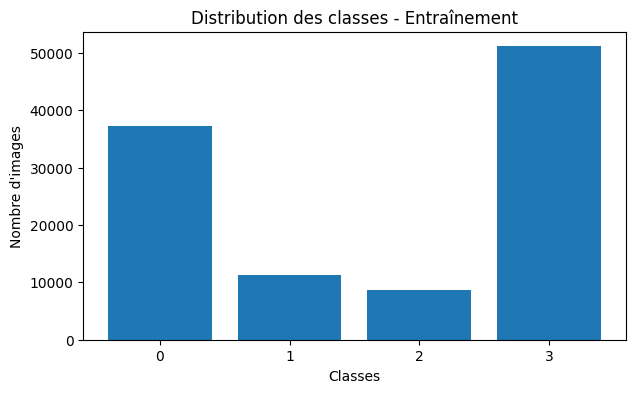

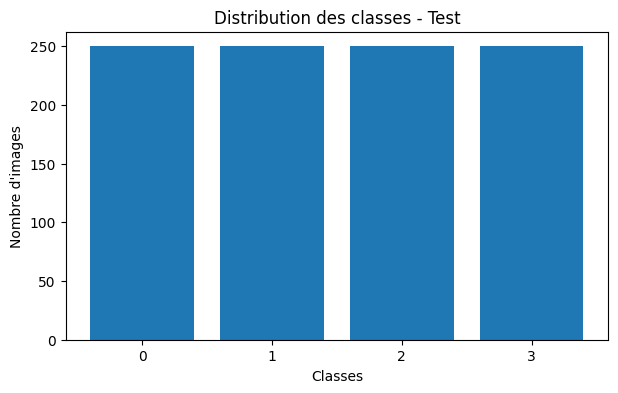

In [ ]:
#Il faut transformer les labels (liste) en matrice pour pouvoir comparer chaque élément de la liste individuellement.
labels_train = np.array(dataset["train"]["label"])
labels_test = np.array(dataset["test"]["label"])

#np.bicount permet de compter combien de fois chacune des labels est répétés dans notre sous-ensemble
nb_train = np.bincount(labels_train)
nb_test = np.bincount(labels_test)

#Proportion d'images de chaque label/classe dans chaque sous-ensemble.
proportion_train = nb_train / total_train
proportion_test = nb_test / total_test

nom_classes = dataset["train"].features["label"].names

print("Entrainement :")

for i in range(4):
  print(f"{nom_classes[i]} : {nb_train[i]} images ({proportion_train[i]:.2%})")

print("\nTest :")

for i in range(4):
    print(f"{nom_classes[i]} : {nb_test[i]} images ({proportion_test[i]:.2%})")

for sous_ensemble, nombres in [("Entraînement", nb_train), ("Test", nb_test)]:

    plt.figure(figsize=(7, 4))
    plt.bar(classes, nombres)
    plt.xlabel("Classes")
    plt.ylabel("Nombre d'images")
    plt.xticks([0, 1, 2, 3])
    plt.title(f"Distribution des classes - {sous_ensemble}")
    plt.show()

**Q4.** Affichez 2 échantillons de chaque classe. Pour chaque image, affichez l'indice et la classe dans le titre. Décrivez les différences que vous observez entre les classes.

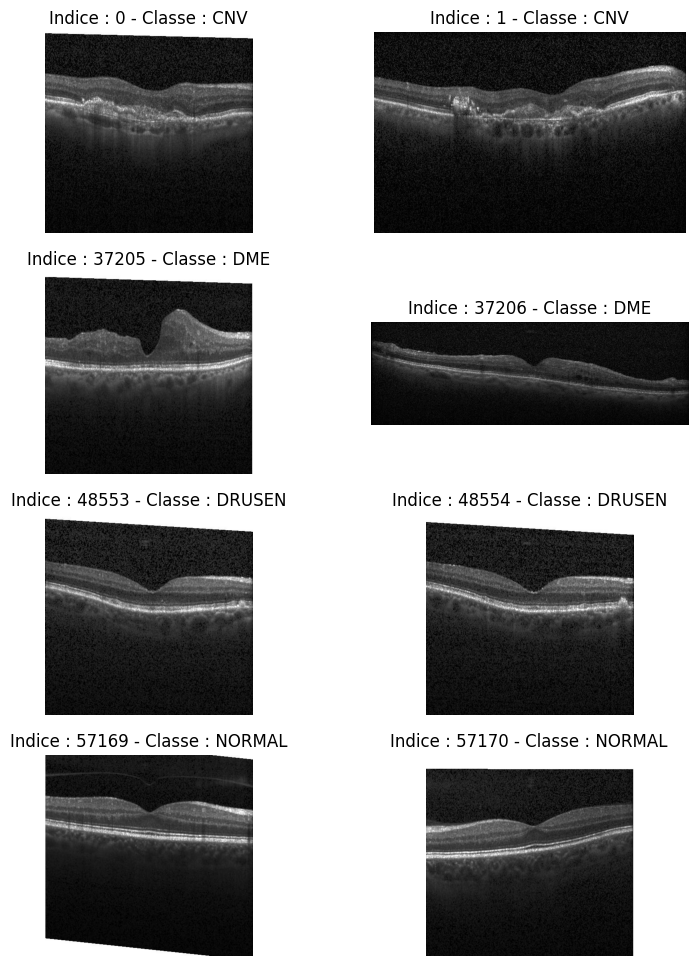

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(9, 12))
for i in range(4):
  #On récupère les images portant l'étiquette de chaque classe.
  #np.where permet d'identifier les positions de ces images et les mettre dans un tuple.
  #label est notre seul indice dans ce tuple, donc indice [0]
  #On récupère les deux premières images de chaque classe grâce au slicing.
    indices = np.where(labels_train == i)[0][:2]
    for j in range(2):
      id = indices[j]
      #On ne veut pas charger toutes les images seulement celles avec les ID déjà identifiés.
      image = dataset["train"][id]["image"]

      axes[i, j].imshow(image, cmap="gray")
      axes[i, j].set_title(f"Indice : {id} - Classe : {nom_classes[i]}")
      axes[i, j].axis("off")

plt.show()


Chacune des classes présente une structure de la rétine caratéristique à elle. Une comparaison par rapport à la classe d'échantillons normaux nous permet d'identifier ces caractéristiques. Sur les images CNV on observe une irrégularité due à la formation de nouveaux vaisseaux sanguins. Sur les images DME on voit des variations de l'épaisseur rétinienne probablement dues à l'accumulation de liquide. Sur les images DRUSEN, on observe aussi des variations moins claires dues aux dépots sous la rétine. Les échantillons normaux présentent une surface lisse et régulière de la rétine.

**Q5.** Vous remarquerez que les images ne sont pas toutes de la même taille. Identifiez les tailles d'images et leur fréquence dans chaque sous-ensemble. Que pouvez-vous observer sur leur distribution? En quoi est-ce que des images de tailles différentes peut être un problème?

In [21]:
for sous_ensemble in ["train", "test"]:
  tailles = []

  for image in dataset[sous_ensemble]:
    tailles.append(image["image"].shape[:2])

  #On veut trouver combien de fois chacune des dimensions est répétée.
  #np.unique retourne chaque taille une fois même si elle se répète,
  #ensuite, on associe à cette classe de tailles un nombre d'occurences (return_counts).
  #On veut comparer (largeur, hauteur) de chaque image comme une paire pas chaque
  #dimension séparément donc on spécifie axis =0.
  dimensions, frequences = np.unique(tailles, axis=0, return_counts=True)

  print(f"\nSous-ensemble : {sous_ensemble}")
  for i in range(len(dimensions)):
    print(f"Dimensions : {dimensions[i]}, Fréquence : {frequences[i]}")


Sous-ensemble : train
Dimensions : [496 384], Fréquence : 21
Dimensions : [496 512], Fréquence : 58037
Dimensions : [496 768], Fréquence : 29745
Dimensions : [ 496 1024], Fréquence : 387
Dimensions : [ 496 1536], Fréquence : 11460
Dimensions : [512 512], Fréquence : 8659

Sous-ensemble : test
Dimensions : [277 642], Fréquence : 1
Dimensions : [455 900], Fréquence : 1
Dimensions : [496 768], Fréquence : 4
Dimensions : [ 496 1024], Fréquence : 942
Dimensions : [ 496 1536], Fréquence : 52


Les images présentent des dimensions variables, avec six tailles différentes dans le sous-ensemble d'entraînement et cinq dans celui de test. Certaines dimensions sont beaucoup plus fréquentes que d'autres (ex. [496 512], [ 496 1024] ). Pour un réseau de neurones ceci peut pourrait poser problème car les images ne seront pas découpés et évalués de la même façon. Il faut donc les redimensionner avant de commencer l'entraînement.  

## Exercice 2.2: Entraînement d'un modèle de classification

**Q1**. Créez un modèle qui n'a pas été pré-entraîné (utilisez la valeur par défaut de `pretrained=False`). Calculez la _loss_ initiale du modèle sur 10% des données d'entraînement. Est-ce que la _loss_ initiale est bien ce à quoi vous vous attendiez?

In [22]:
train_loader, val_loader, test_loader = get_dataloaders(dataset, batch_size=64, train_subset=0.1)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [23]:
model, optimizer = get_model_and_optimizer(pretrained=False)
loss_initiale, accuracy_initiale = validate(model, train_loader)

print(f"Loss initiale : {loss_initiale:.2f}")

Validation:   0%|          | 0/161 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
                                                             

Loss initiale : 1.39


La loss attendue = ln(K) avec K = 4 classes. Donc, loss_attendue = ln(4) = 1.39. Cette valeur correspond exactement à la loss_initiale obtenue.

**Q2**. Entraînez votre modèle sur 10% des données d'entraînement (20 époques devraient suffire). Affichez la courbe d'évolution de votre erreur (_loss_) d'entraînement. Au long de votre entraînement, validez la performance de votre modèle sur l'ensemble de validation et affichez la _loss_ et l'_accuracy_ en fonction de l'époque.

Faites le suivi de l'_accuracy_ et identifiez la plus haute valeur obtenue au cours de l'entraînement. Faites une sauvegarde du modèle lorsque vous obtenez cette meilleure _accuracy_.

N.B.: Pour cette question, vous n'avez pas besoin de faire une validation à chaque époque. Vous pouvez choisir un intervalle plus grand (e.g. toutes les 2 époques) pour diminuer le temps de calcul.

In [24]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [25]:
import os

dossier = "/content/drive/MyDrive/GBM8770_TP2"
os.makedirs(dossier, exist_ok=True)

In [26]:
loss_val, accuracy_val = validate(model, val_loader)

print(f"Loss de validation : {loss_val:.4f}")
print(f"Accuracy de validation : {accuracy_val:.2%}")

Loss de validation : 1.3863
Accuracy de validation : 31.46%


Terminé
Meilleure accuracy de validation : 87.56%


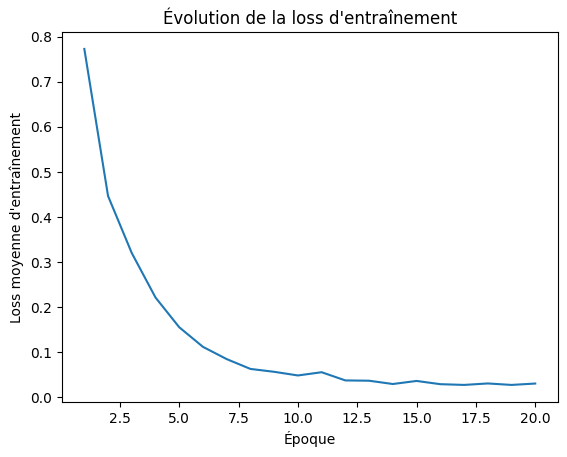

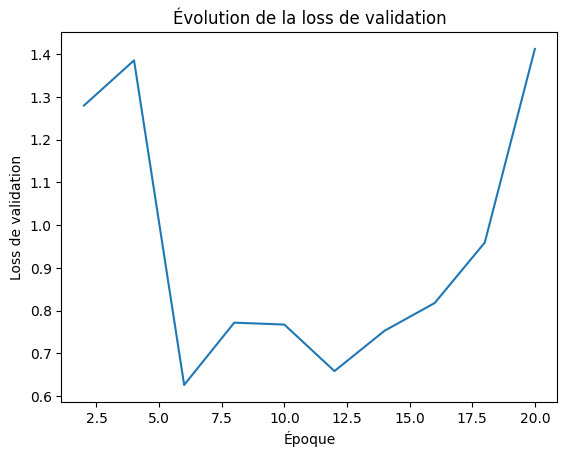

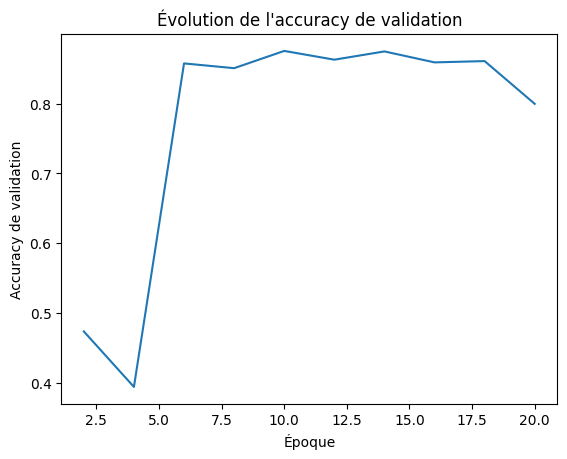

In [27]:
loss_train = []
loss_validation = []
accuracy_validation = []
epoques_validation = []

meilleure_accuracy = 0

for epoch in range(20):

    # Entraînement
    losses = train_epoch(model, train_loader, optimizer)  #retourne une liste de losses
    loss_train.append(np.mean(losses))  #On veut comparer à chaque époque, pas à chaque batch


    # Validation à chaque 2 époques
    if (epoch + 1) % 2 == 0:
        loss_val, accuracy_val = validate(model, val_loader)

        loss_validation.append(loss_val)
        accuracy_validation.append(accuracy_val)
        epoques_validation.append(epoch + 1)

        # Sauvegarder le meilleur modèle lorsque meilleure accuracy atteinte
        if accuracy_val > meilleure_accuracy:
            meilleure_accuracy = accuracy_val
            #Enregistrement dans GoogleDrive car on travaille dans Colab
            torch.save(model.state_dict(), dossier + "/meilleur_modele.pt")

print("Terminé")
print(f"Meilleure accuracy de validation : {meilleure_accuracy:.2%}")

plt.plot(range(1, 21), loss_train)
plt.xlabel("Époque")
plt.ylabel("Loss moyenne d'entraînement")
plt.title("Évolution de la loss d'entraînement")
plt.show()

plt.plot(epoques_validation, loss_validation)
plt.xlabel("Époque")
plt.ylabel("Loss de validation")
plt.title("Évolution de la loss de validation")
plt.show()

plt.plot(epoques_validation, accuracy_validation)
plt.xlabel("Époque")
plt.ylabel("Accuracy de validation")
plt.title("Évolution de l'accuracy de validation")
plt.show()

## Apprentissage par transfert

**Q1**. Étant données les différences marquées entre les caractéristiques des images d'ImageNet (des chats, des chiens, des autobus, des spatules, etc.) et les images OCT de la rétine, pensez-vous qu'utiliser un modèle pré-entraîné sur ImageNet va aider vos performances de classification? Expliquez votre raisonnement.

Utiliser un modèle pré-entraîné aide quand-même les performances de classifiations de notre modèle. Même si les images sont différentes, le modèle apprendra a identifié des caractéristiques visuelles générales comme les formes ou les contours par exemple ce qui pourrait être utile pour distinguer des caractéristiques des maladies rétiniennes.

**Q2**. Affinez pendant au moins 10 époques un modèle pré-entraîné. Créez le en utilisant l'argument `pretrained=True`. Durant l'entraînement du modèle, faites une sauvegarde du modèle lorsque vous obtenez la meilleure _accuracy_. Affichez les courbes d'évolution de votre _loss_ d'entraînement, et de votre _loss_ et _accuracy_ de validation.

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 148MB/s]
Training:   0%|          | 0/161 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
                                                           

Terminé
Meilleure accuracy de validation : 95.68%


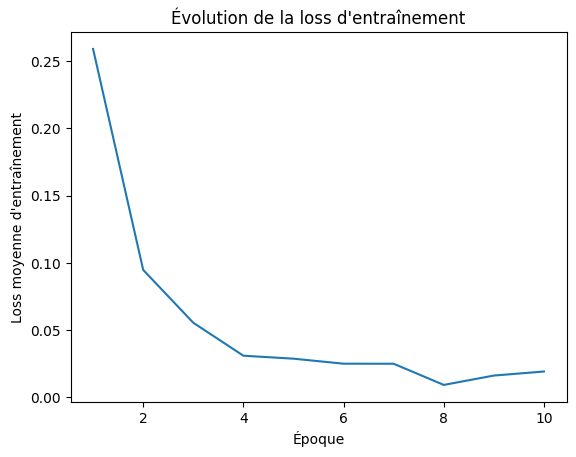

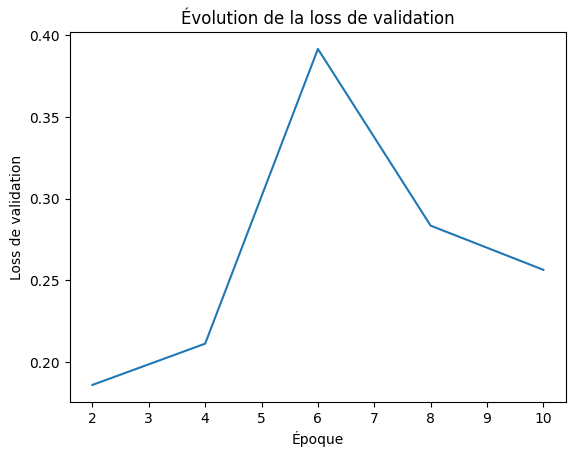

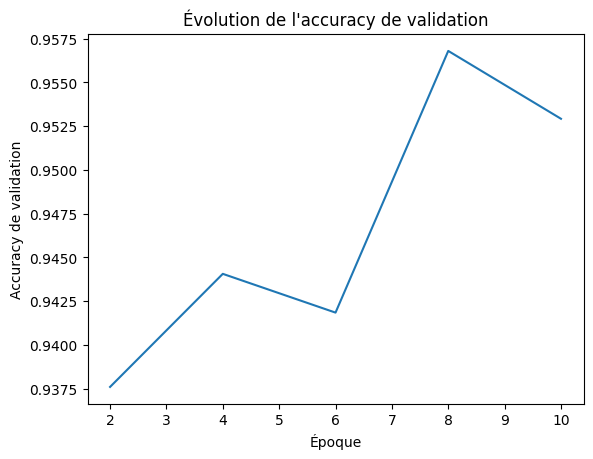

In [30]:
#On réutilise la même structure de code de l'entraînement précédent
#L'autre modèle est déjà entraîné. On a les résultats. On peut réutiliser les mêmes noms, variables...

loss_train = []
loss_validation = []
accuracy_validation = []
epoques_validation = []

meilleure_accuracy = 0

model, optimizer = get_model_and_optimizer(pretrained=True)

for epoch in range(10):

    # Entraînement
    losses = train_epoch(model, train_loader, optimizer)  #retourne une liste de losses
    loss_train.append(np.mean(losses))  #On veut comparer à chaque époque, pas à chaque batch


    # Validation à chaque 2 époques
    if (epoch + 1) % 2 == 0:
        loss_val, accuracy_val = validate(model, val_loader)

        loss_validation.append(loss_val)
        accuracy_validation.append(accuracy_val)
        epoques_validation.append(epoch + 1)

        # Sauvegarder le meilleur modèle lorsque meilleure accuracy atteinte
        if accuracy_val > meilleure_accuracy:
            meilleure_accuracy = accuracy_val
            #Enregistrement dans GoogleDrive car on travaille dans Colab
            torch.save(model.state_dict(), dossier + "/meilleur_modele_pretrained.pt")

print("Terminé")
print(f"Meilleure accuracy de validation : {meilleure_accuracy:.2%}")

plt.plot(range(1, 11), loss_train)
plt.xlabel("Époque")
plt.ylabel("Loss moyenne d'entraînement")
plt.title("Évolution de la loss d'entraînement")
plt.show()

plt.plot(epoques_validation, loss_validation)
plt.xlabel("Époque")
plt.ylabel("Loss de validation")
plt.title("Évolution de la loss de validation")
plt.show()

plt.plot(epoques_validation, accuracy_validation)
plt.xlabel("Époque")
plt.ylabel("Accuracy de validation")
plt.title("Évolution de l'accuracy de validation")
plt.show()

**Q3.** Comparez les performances de votre modèle pré-entraîné avec celles de votre modèle non pré-entraîné. Qu'en concluez-vous?

Le modèle pré-entraîné sur ImageNet donne une meilleure accuracy de validation (95.68% vs 87.56% pour le modèle non pré-entraîné), et ce à un nombre d'époques inférieur de 50%. La loss finale de validation est également inférieure pour le modèle pré-entraîné (environ 0.27). L'allure du graphique de loss de validation pour le modèle non pré-entraîné montre un surapprentissage vers la fin des époques contrairement au modèle pré-entraîné. Ceci confirme notre idée initiale que le pré-entraînement du modèle sur des images génériques de ImageNet améliore la performance du modèle pour des images OCT de la rétine.

## Évaluation finale

**Q1**. Évaluez votre meilleur modèle sur l'ensemble de test. Affichez la _loss_ et l'_accuracy_ finale.

In [34]:
#On utilise le modèle préentraîné qui a montré une meilleure accuracy et performance.
saved_model = get_model_and_optimizer(pretrained=True)[0]
saved_state_dict = torch.load(dossier + "/meilleur_modele_pretrained.pt", map_location = "cpu")
saved_model.load_state_dict(saved_state_dict)

loss_test, accuracy_test = validate(saved_model, test_loader)

print(f"Loss de test : {loss_test:.2f}")
print(f"Accuracy de test : {accuracy_test:.2%}")

Validation:   0%|          | 0/16 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
                                                           

Loss de test : 0.64
Accuracy de test : 88.90%


**Q2**. Commentez les performances de votre modèle sur l'ensemble de test et comparez-les à celles obtenues sur l'ensemble de validation.

Le modèle obtient une accuracy de test 88.90% inférieure à 95.68% obtenue sur le sous-ensemble de validation. Il obtient aussi une loss de 0.64 valeur supérieure à 0.24 obtenue à la fin de l'entraînement de sous-ensemble de validation. Ceci indique que le modèle est moins performant sur l'ensemble test et donc que sa capacité de généralisation n'est pas otimale.  


**Q3**. Pourquoi est-il important de maintenir un ensemble de test séparé de l'ensemble de validation? Que se passerait-il si on n'avait que deux ensembles (entraînement et validation/test) plutôt que trois (entraînement, validation, test)?

Il est important de maintenir un ensemble de test séparé de l'ensemble de validation puisque ce dernier nous permet de faire le suivi de la performance et de choisisr le meilleur modèle avec la meilleure accuracy. Alors que l'ensemble test nous permet d'évaluer la performance réelle sur un batch complètement nouveau pour le modèle. Si on utilise le même ensemble pour valider et tester on risque de surestimer la performance de notre modèle puisque les mêmes donnnées ont été présentées au modèle pour le sélectionner et pour le tester.

**Q4**. Au sein de l’ensemble de test, identifiez

<!-- | Une image CNV correctement identifiée comme CNV | Une image CNV incorrectement identifiée comme DME |
 -->


| Une image CNV correctement identifiée comme CNV | Une image CNV incorrectement identifiée comme DME | Une image CNV incorrectement identifiée comme Drusen | Une image CNV incorrectement identifiée comme normale |
|---|---|---|---|
| Une image DME incorrectement identifiée comme CNV | Une image DME correctement identifiée comme DME | Une image DME incorrectement identifiée comme Drusen | Une image DME incorrectement identifiée comme normale |
| Une image Drusen incorrectement identifiée comme CNV | Une image Drusen incorrectement identifiée comme DME | Une image Drusen correctement identifiée comme Drusen | Une image Drusen incorrectement identifiée comme normale |
| Une image normale incorrectement identifiée comme CNV | Une image normale incorrectement identifiée comme DME | Une image normale incorrectement identifiée comme Drusen | Une image normale correctement identifiée comme normale |

Validation:   0%|          | 0/16 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


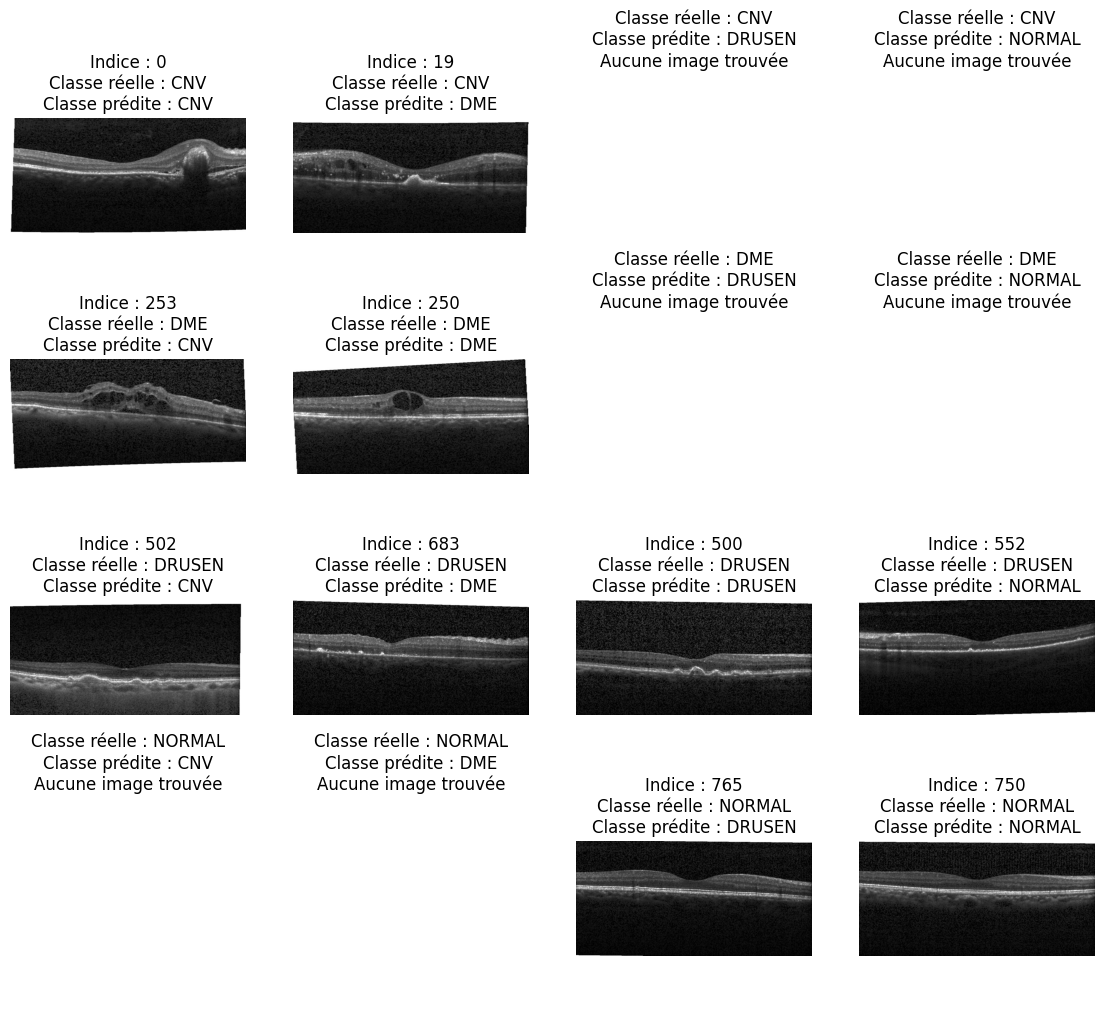

In [49]:
#On veut récupérer les prédictions de notre modèle, on utilise donc validate.
loss_test, accuracy_test, predictions = validate(saved_model, test_loader, return_preds = True)

#Il faut remettre les listes qu'elle retourne sous forme de array pour pouvoir comparer avec les labels.
predictions = np.array(predictions)

fig, axes = plt.subplots(4, 4, figsize=(14, 12))

#Pour chaque classe réelle, on veut troouver une image avec les 4 prédictions possibles.
for i in range(4):
  for j in range(4):
    #On vérifie les 2 conditions en même temps.
    #On trouve les positions (id) des images qui vérifient les 2 conditions.
    id = np.where((labels_test == i) & (predictions == j))[0]

    #Si au moins une image est trouvée, on prend la première.
    if len(id) > 0:
      id_image = id[0]
      image = dataset["test"][id_image]["image"]
      axes[i, j].imshow(image, cmap="gray")
      axes[i, j].set_title(f"Indice : {id_image}\nClasse réelle : {nom_classes[i]}\nClasse prédite : {nom_classes[j]}")
    else:
      axes[i, j].set_title(f"Classe réelle : {nom_classes[i]}\nClasse prédite : {nom_classes[j]}\nAucune image trouvée")
    axes[i, j].axis("off")

plt.show()

**Q5**. Au vu des performances de votre meilleur modèle sur les données de test, seriez-vous à l'aise d'intégrer ce modèle dans des protocoles cliniques pour aider au diagnostic? Justifiez votre réponse.

Le modèle classe correctement les images selon leur classe réelle dans la plupart des cas, cependant il n'est pas toujours performant. Il confond des images CNV et DME. Mais n'identifie jamais une image CNV ou DME comme normale, ce qui est un avantage. Il est clairement moins performant pour le cas de DRUSEN pour lequel il fait des erreurs avec toutes les autres classes (incluant la classe normale ce qui peut être dangereux). Donc, pour le moment, le modèle peut être intégré dans des protocoles cliniques pour aider à diagnostiquer la CNV OU DME sans trancher sur le type d'anomalie. Sinon, le modèle demande encore plus de travail pour la classification de DRUSEN et la différenciation entre CNV et DME.

De plus, on n'a pas d'indications sur la fréquences de ces erreurs de classification donc on ne peut pas prendre une décision finale.

## Visualisation de l'espace latent

**Q1**. Utilisez la fonction `get_embeddings` pour extraire les _vecteurs latents_ des images de l'ensemble de test issus
1. d'un modèle aléatoirement initialisé;
2. d'un modèle pré-entraîné sur ImageNet, mais non affiné;
3. de votre modèle entraîné (sans pré-entraînement);
4. de votre modèle affiné (avec pré-entraînement).

In [53]:
#On recréé les 4 modèles.

#Modèle aléatoirement initialisé
modele_aleatoire = get_model_and_optimizer(pretrained=False)[0]

#Modèle pré-entraîné sur ImagenNet mais non affiné
modele_pretrained = get_model_and_optimizer(pretrained=True)[0]

#Modèle entraîné (sans pré-entraînement)
modele_entraine = get_model_and_optimizer(pretrained=False)[0]
saved_state_dict = torch.load(dossier + "/meilleur_modele.pt", map_location = "cpu")
modele_entraine.load_state_dict(saved_state_dict)

#Modèle affiné (avec pré-entraînement)
modele_affine = get_model_and_optimizer(pretrained=True)[0]
saved_state_dict = torch.load(dossier + "/meilleur_modele_pretrained.pt", map_location = "cpu")
modele_affine.load_state_dict(saved_state_dict)

#On extraie les embeddings.

embed_aleatoire = get_embeddings(modele_aleatoire, test_loader)
embed_pretrained = get_embeddings(modele_pretrained, test_loader)
embed_entraine = get_embeddings(modele_entraine, test_loader)
embed_affine = get_embeddings(modele_affine, test_loader)

**Q2**. Pour chacun des trois ensembles de vecteurs latents obtenus à la question précédente, utilisez la méthode t-SNE pour réduire la dimensionnalité des vecteurs à 2D. Affichez les résultats dans un graphique de dispersion (_scatter plot_), où chaque point représente une image, et où la couleur du point indique la classe de l'image. Commentez vos observations.

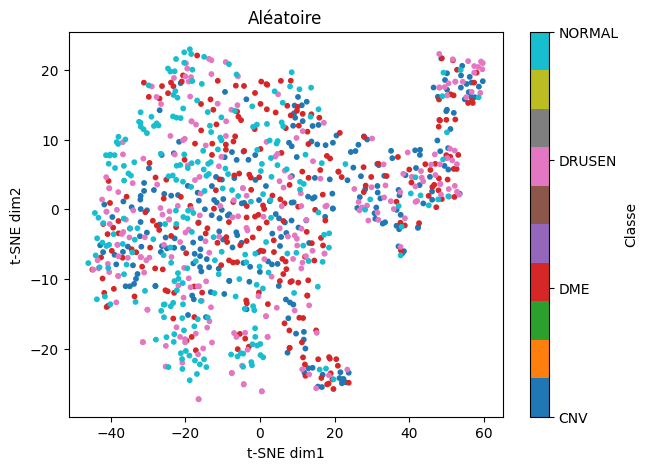

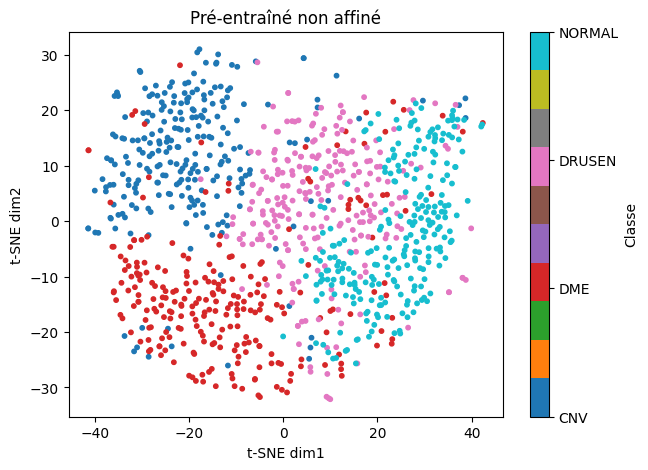

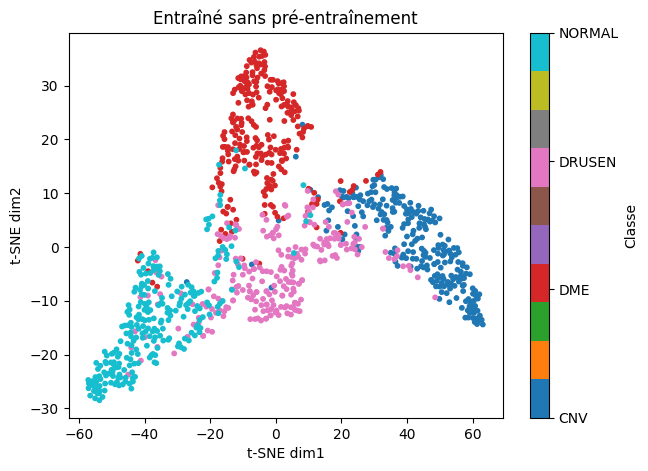

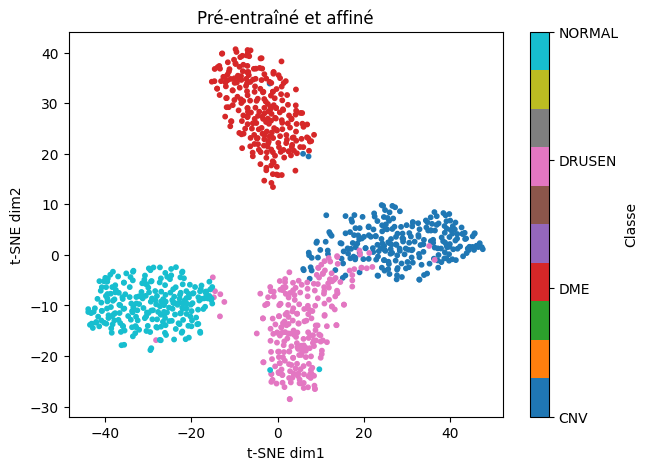

In [56]:
from sklearn.manifold import TSNE

#Modèle aléatoirement initialisé
tsne_aleatoire = TSNE(n_components=2)
tsne_features_aleatoire = tsne_aleatoire.fit_transform(embed_aleatoire)

#Modèle pré-entraîné sur ImagenNet mais non affiné
tsne_pretrained = TSNE(n_components=2)
tsne_features_pretrained = tsne_pretrained.fit_transform(embed_pretrained)

#Modèle entraîné (sans pré-entraînement)
tsne_entraine = TSNE(n_components=2)
tsne_features_entraine = tsne_entraine.fit_transform(embed_entraine)

#Modèle affiné (avec pré-entraînement)
tsne_affine = TSNE(n_components=2)
tsne_features_affine = tsne_affine.fit_transform(embed_affine)

#Affichage des résultats sur un scatter plot

resultats = [("Aléatoire", tsne_features_aleatoire),
            ("Pré-entraîné non affiné", tsne_features_pretrained),
            ("Entraîné sans pré-entraînement", tsne_features_entraine),
            ("Pré-entraîné et affiné", tsne_features_affine)]

for titre, points in resultats:

    plt.figure(figsize=(7, 5))
    #tsne retourne un tableau avec 2 colonnes pour chaque image: dim1, dim2
    #On veut donner une couleur à chaque classe/label donc on définit c(color) et cmap.
    plt.scatter(points[:, 0], points[:, 1], c=labels_test, cmap="tab10", s=10)
    plt.xlabel("t-SNE dim1")
    plt.ylabel("t-SNE dim2")
    plt.title(titre)
    plt.colorbar(ticks=[0, 1, 2, 3], label="Classe").ax.set_yticklabels(nom_classes)
    plt.show()

On remarque que le modèle aléatoire initialisé initialement présente une dispersion importante entre les classes sans aucune séparation. Plus le modèle est entraîné (sur n'importe quel dataset), plus il devient performant dans la sécéstration des classes. Comme attendu, on remarque que l'entraînement sur les OCT des rétines est beaucoup plsu efficace que sur ImageNet. Cependant, le modèle pré-entraîné présente une meilleure séparation entre les classes que le modèle sans pré-entraînement sur le même dataset de test.

De façon plus détaillée, sur le modèle pré=entraîné et affiné, on observe une séparation presque parfaite pour les classes NORMAL, DME et CNV. Cependant, on observe un chevauchement important entre la classe DRUSEN et les autres classes, donc une difficulté à l'identifier ou la séparer des autres. Ceci concorde avec les conclusions précédentes.